In [ ]:
# CNN - Convolutional Neural Network for Image Classification
# Dataset: digits (8x8 images, 0-9) - built into sklearn, no download needed
#
# Needs: pip install tensorflow
#
# If you want the full 28x28 MNIST from Kaggle instead, swap the data-loading
# section for pd.read_csv() on that file - the CNN architecture below works
# the same either way, just update input_shape to (28, 28, 1).

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)
np.random.seed(42)

digits = load_digits()
X = digits.images     # shape: (1797, 8, 8) - already 2D images, not flattened
y = digits.target

print("Images shape:", X.shape)
print("Labels shape:", y.shape)


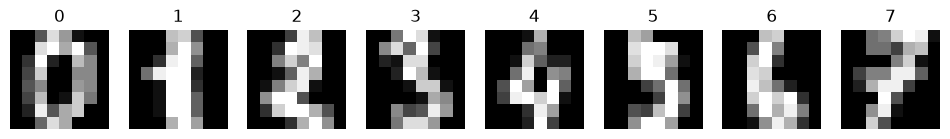

Train shape: (1437, 8, 8, 1)  Test shape: (360, 8, 8, 1)


In [2]:
# ---- 1. Look at a few sample images ----
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axes):
    ax.imshow(X[i], cmap="gray")
    ax.set_title(str(y[i]))
    ax.axis("off")
plt.show()

# ---- 2. Preprocess for a CNN ----
# CNNs expect a "channel" dimension even for grayscale images: (height, width, channels)
X = X.reshape(-1, 8, 8, 1)

# scale pixel values from 0-16 (this dataset's range) down to 0-1
X = X / 16.0

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

In [3]:
# ---- 3. Build the CNN ----
model = keras.Sequential([
    layers.Input(shape=(8, 8, 1)),

    # convolution layer: slides small filters across the image, learning to
    # detect edges/patterns - this is what makes CNNs good at images
    layers.Conv2D(16, kernel_size=(3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D(pool_size=(2, 2)),   # downsamples, keeps strongest signals

    layers.Conv2D(32, kernel_size=(3, 3), activation="relu", padding="same"),

    layers.Flatten(),                        # collapse to 1D before dense layers
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),                     # randomly "turns off" neurons during
                                              # training to reduce overfitting
    layers.Dense(10, activation="softmax")   # 10 classes (digits 0-9)
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 8, 8, 16)            │             160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 4, 4, 16)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 4, 4, 32)            │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │          16,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │             330 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 21,546 (84.16 KB)

 Trainable params: 21,546 (84.16 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# ---- 4. Compile ----
# sparse_categorical_crossentropy because labels are plain integers (0-9),
# not one-hot encoded
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

# ---- 5. Train ----
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    verbose=1
)

# ---- 6. Evaluate ----
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest accuracy: {test_acc:.4f}")


Epoch 1/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.2681 - loss: 2.1883 - val_accuracy: 0.5382 - val_loss: 2.0001
Epoch 2/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5161 - loss: 1.6842 - val_accuracy: 0.8021 - val_loss: 1.2233
Epoch 3/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6963 - loss: 1.0366 - val_accuracy: 0.8889 - val_loss: 0.6497
Epoch 4/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7737 - loss: 0.7341 - val_accuracy: 0.9097 - val_loss: 0.4494
Epoch 5/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8190 - loss: 0.5769 - val_accuracy: 0.9132 - val_loss: 0.3480
Epoch 6/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8486 - loss: 0.4991 - val_accuracy: 0.9062 - val_loss: 0.3071
Epoch 7/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8555 - loss: 0.4342 - val_accuracy: 0.9236 - val_loss: 0.2578
Epoch 8/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8790 - loss: 0.3952 - val_accuracy: 0.9375 - val_loss:

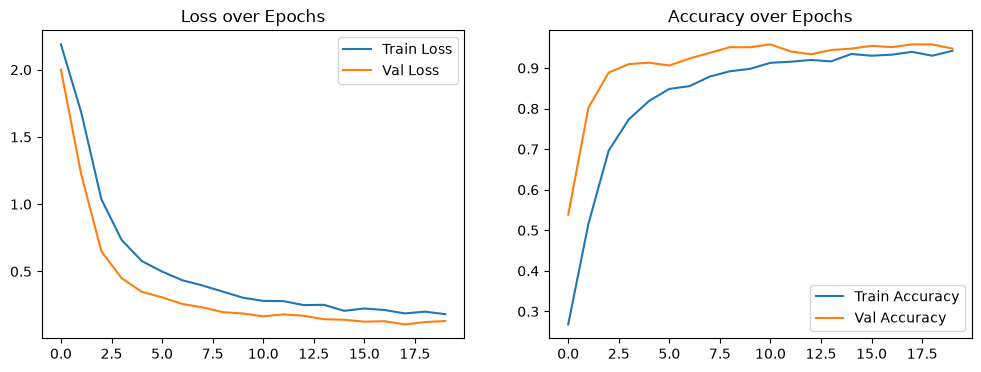

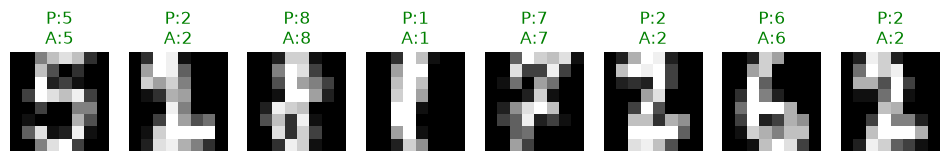

In [5]:
# ---- 7. Plot training curves ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="Train Loss")
axes[0].plot(history.history["val_loss"], label="Val Loss")
axes[0].set_title("Loss over Epochs")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Train Accuracy")
axes[1].plot(history.history["val_accuracy"], label="Val Accuracy")
axes[1].set_title("Accuracy over Epochs")
axes[1].legend()
plt.show()

# ---- 8. Look at predictions vs actual on test samples ----
predictions = model.predict(X_test[:8], verbose=0)
predicted_labels = np.argmax(predictions, axis=1)

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axes):
    ax.imshow(X_test[i].reshape(8, 8), cmap="gray")
    color = "green" if predicted_labels[i] == y_test[i] else "red"
    ax.set_title(f"P:{predicted_labels[i]}\nA:{y_test[i]}", color=color)
    ax.axis("off")
plt.show()


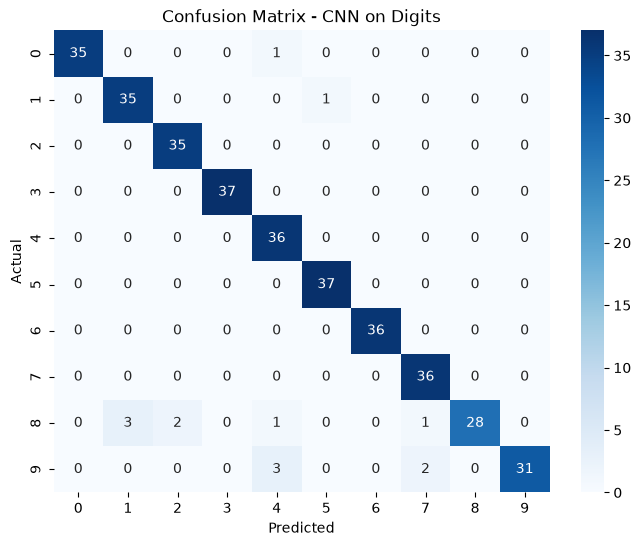

In [6]:
# ---- 9. Confusion matrix ----
from sklearn.metrics import confusion_matrix
import seaborn as sns

y_pred_all = np.argmax(model.predict(X_test, verbose=0), axis=1)
cm = confusion_matrix(y_test, y_pred_all)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - CNN on Digits")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()